# LAB2 - Bài 2

## Câu 1

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

In [2]:
train = pd.read_csv('./Dataset/adult.data.csv', skipinitialspace=True)
test = pd.read_csv('./Dataset/adult.test.csv', skipinitialspace=True)

In [3]:
print("Number of training data:", len(train))
print("Number of test data:", len(test))

Number of training data: 32561
Number of test data: 16281


Đặng Phan Duy - 6451071010

In [4]:
train.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


Đặng Phan Duy - 6451071010

In [5]:
test.head()

,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


Đặng Phan Duy - 6451071010

## Câu 2

In [6]:
# Xóa những dòng có chứa dữ liệu trống (ký hiệu bằng dấu '?')
train = train.replace('?', np.nan).dropna()
test = test.replace('?', np.nan).dropna()

# Xóa cột final weight 'fnlwgt' trong dữ liệu huấn luyện
train = train.drop('fnlwgt', axis=1)

print("Number of training data:", len(train))
print("Number of test data:", len(test))

Number of training data: 30162
Number of test data: 15060


Đặng Phan Duy - 6451071010

In [7]:
# Nối dữ liệu huấn luyện và kiểm thử lại với nhau
data = pd.concat([train, test], ignore_index=True)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             45222 non-null  int64 
 1   workclass       45222 non-null  object
 2   education       45222 non-null  object
 3   education-num   45222 non-null  int64 
 4   marital-status  45222 non-null  object
 5   occupation      45222 non-null  object
 6   relationship    45222 non-null  object
 7   race            45222 non-null  object
 8   sex             45222 non-null  object
 9   capital-gain    45222 non-null  int64 
 10  capital-loss    45222 non-null  int64 
 11  hours-per-week  45222 non-null  int64 
 12  native-country  45222 non-null  object
 13  income          45222 non-null  object
dtypes: int64(5), object(9)
memory usage: 4.8+ MB


Đặng Phan Duy - 6451071010

## Câu 3

<Axes: >

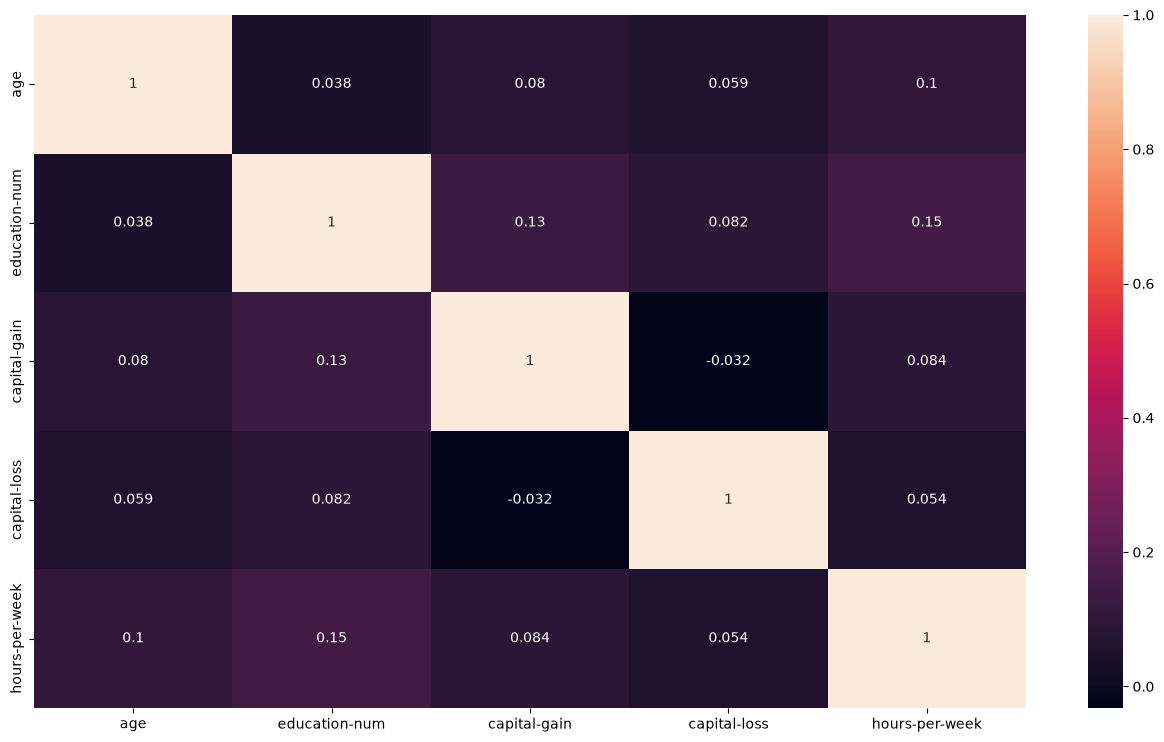

In [9]:
plt.figure(figsize=(16,9))
sns.heatmap(data.corr(method='pearson', numeric_only=True), annot=True)

Đặng Phan Duy - 6451071010

Nhận xét: các giá trị tương đồng giữa các cột đều rất thấp (đều nhỏ hơn 0.2), không có thuộc tính nào tương đồng cao với nhau nên không cần loại bỏ cột nào.

## Câu 4

In [10]:
features = data.drop('income', axis=1)
labels = data['income']

## Câu 5

In [11]:
features.select_dtypes(exclude=['int64']).columns

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')

Đặng Phan Duy - 6451071010

In [12]:
features_onehot = pd.get_dummies(features, columns=features.select_dtypes(exclude=['int64']).columns)
features_onehot

,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,50,13,0,0,13,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False
2,38,9,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
3,53,7,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
4,28,13,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45217,33,13,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
45218,39,13,0,0,36,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
45219,38,13,0,0,50,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
45220,44,13,5455,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False


Đặng Phan Duy - 6451071010

## Câu 6

In [13]:
X_train = features_onehot[:30162]
X_test = features_onehot[30162:]
y_train = labels[:30162]
y_test = labels[30162:]

## Câu 7

In [14]:
clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
#Train Decision Tree Classifer
clf.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

Đặng Phan Duy - 6451071010

In [15]:
#Predict the response for test dataset
tree_pred = clf.predict(X_test)

# Model Accuracy, how often is the classifier correct?
tree_score = metrics.accuracy_score(y_test, tree_pred)
print("Accuracy:", tree_score)
print("Report:", metrics.classification_report(y_test, tree_pred))

Accuracy: 0.8175298804780876
Report:               precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     11360
        >50K       0.63      0.62      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.82      0.82      0.82     15060



Đặng Phan Duy - 6451071010

In [16]:
tree_cm = metrics.confusion_matrix(y_test, tree_pred)

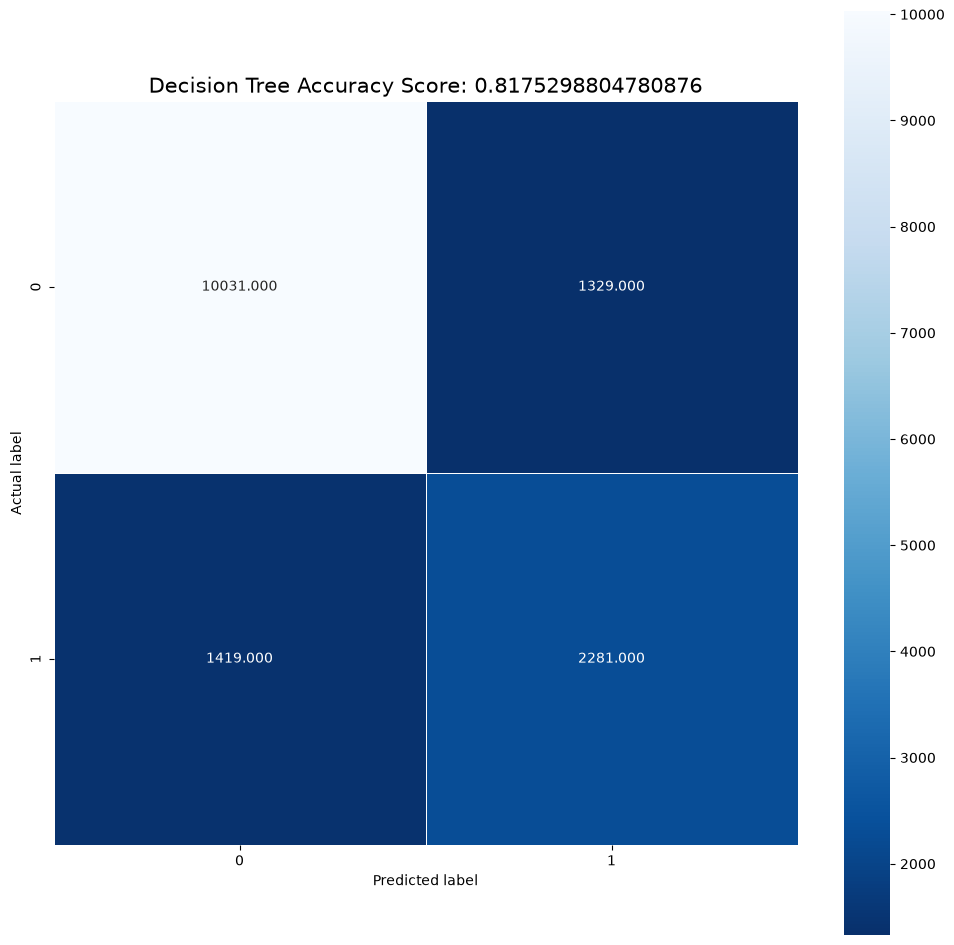

In [17]:
plt.figure(figsize=(12,12))
sns.heatmap(tree_cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Decision Tree Accuracy Score: {0}'.format(tree_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

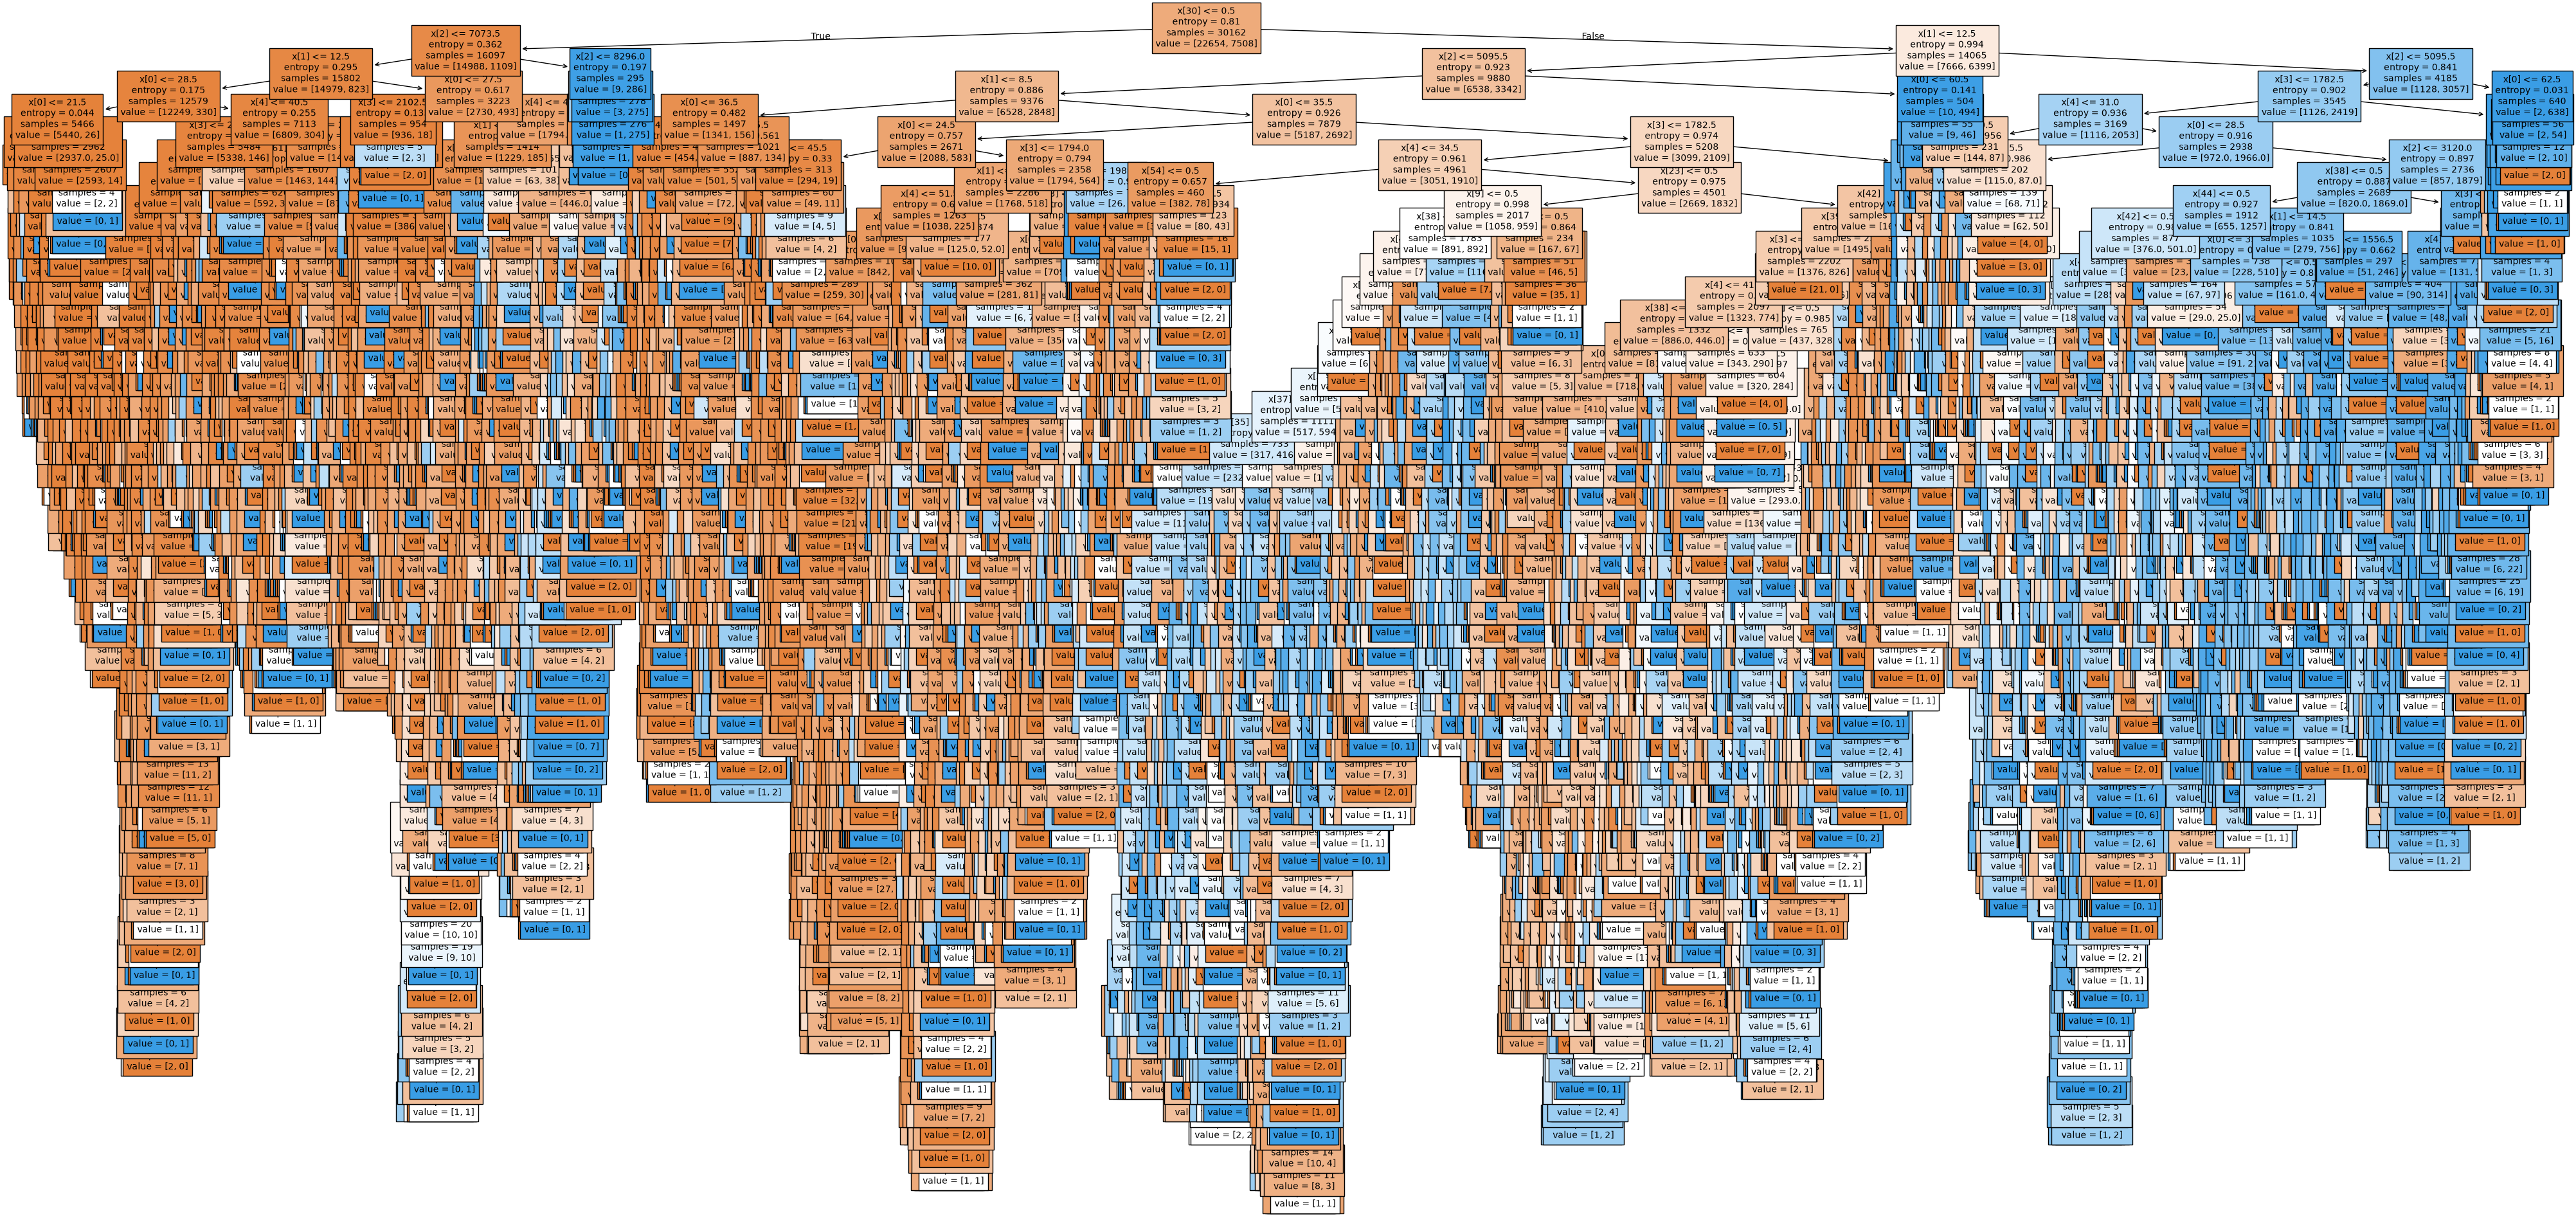

In [18]:
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf, filled=True, fontsize=10)
plt.savefig('decision_tree', dpi=100)
plt.show()

Đặng Phan Duy - 6451071010

## Câu 8

In [19]:
clf_gini = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
#Train Decision Tree Classifer
clf_gini.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

Đặng Phan Duy - 6451071010

In [20]:
#Predict the response for test dataset
gini_pred = clf_gini.predict(X_test)

# Model Accuracy, how often is the classifier correct?
gini_score = metrics.accuracy_score(y_test, gini_pred)
print("Accuracy:", gini_score)
print("Report:", metrics.classification_report(y_test, gini_pred))

Accuracy: 0.8122841965471448
Report:               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.74     15060
weighted avg       0.81      0.81      0.81     15060



Đặng Phan Duy - 6451071010

In [21]:
gini_cm = metrics.confusion_matrix(y_test, gini_pred)

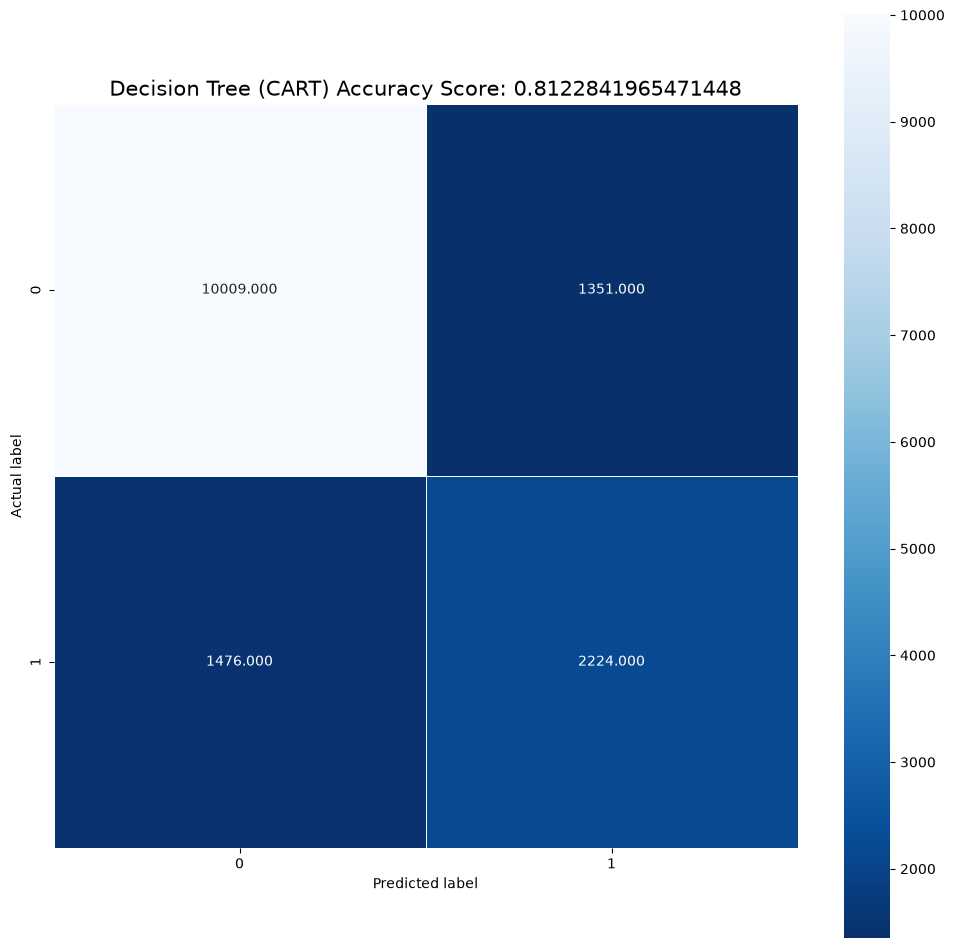

In [22]:
plt.figure(figsize=(12,12))
sns.heatmap(gini_cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Decision Tree (CART) Accuracy Score: {0}'.format(gini_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

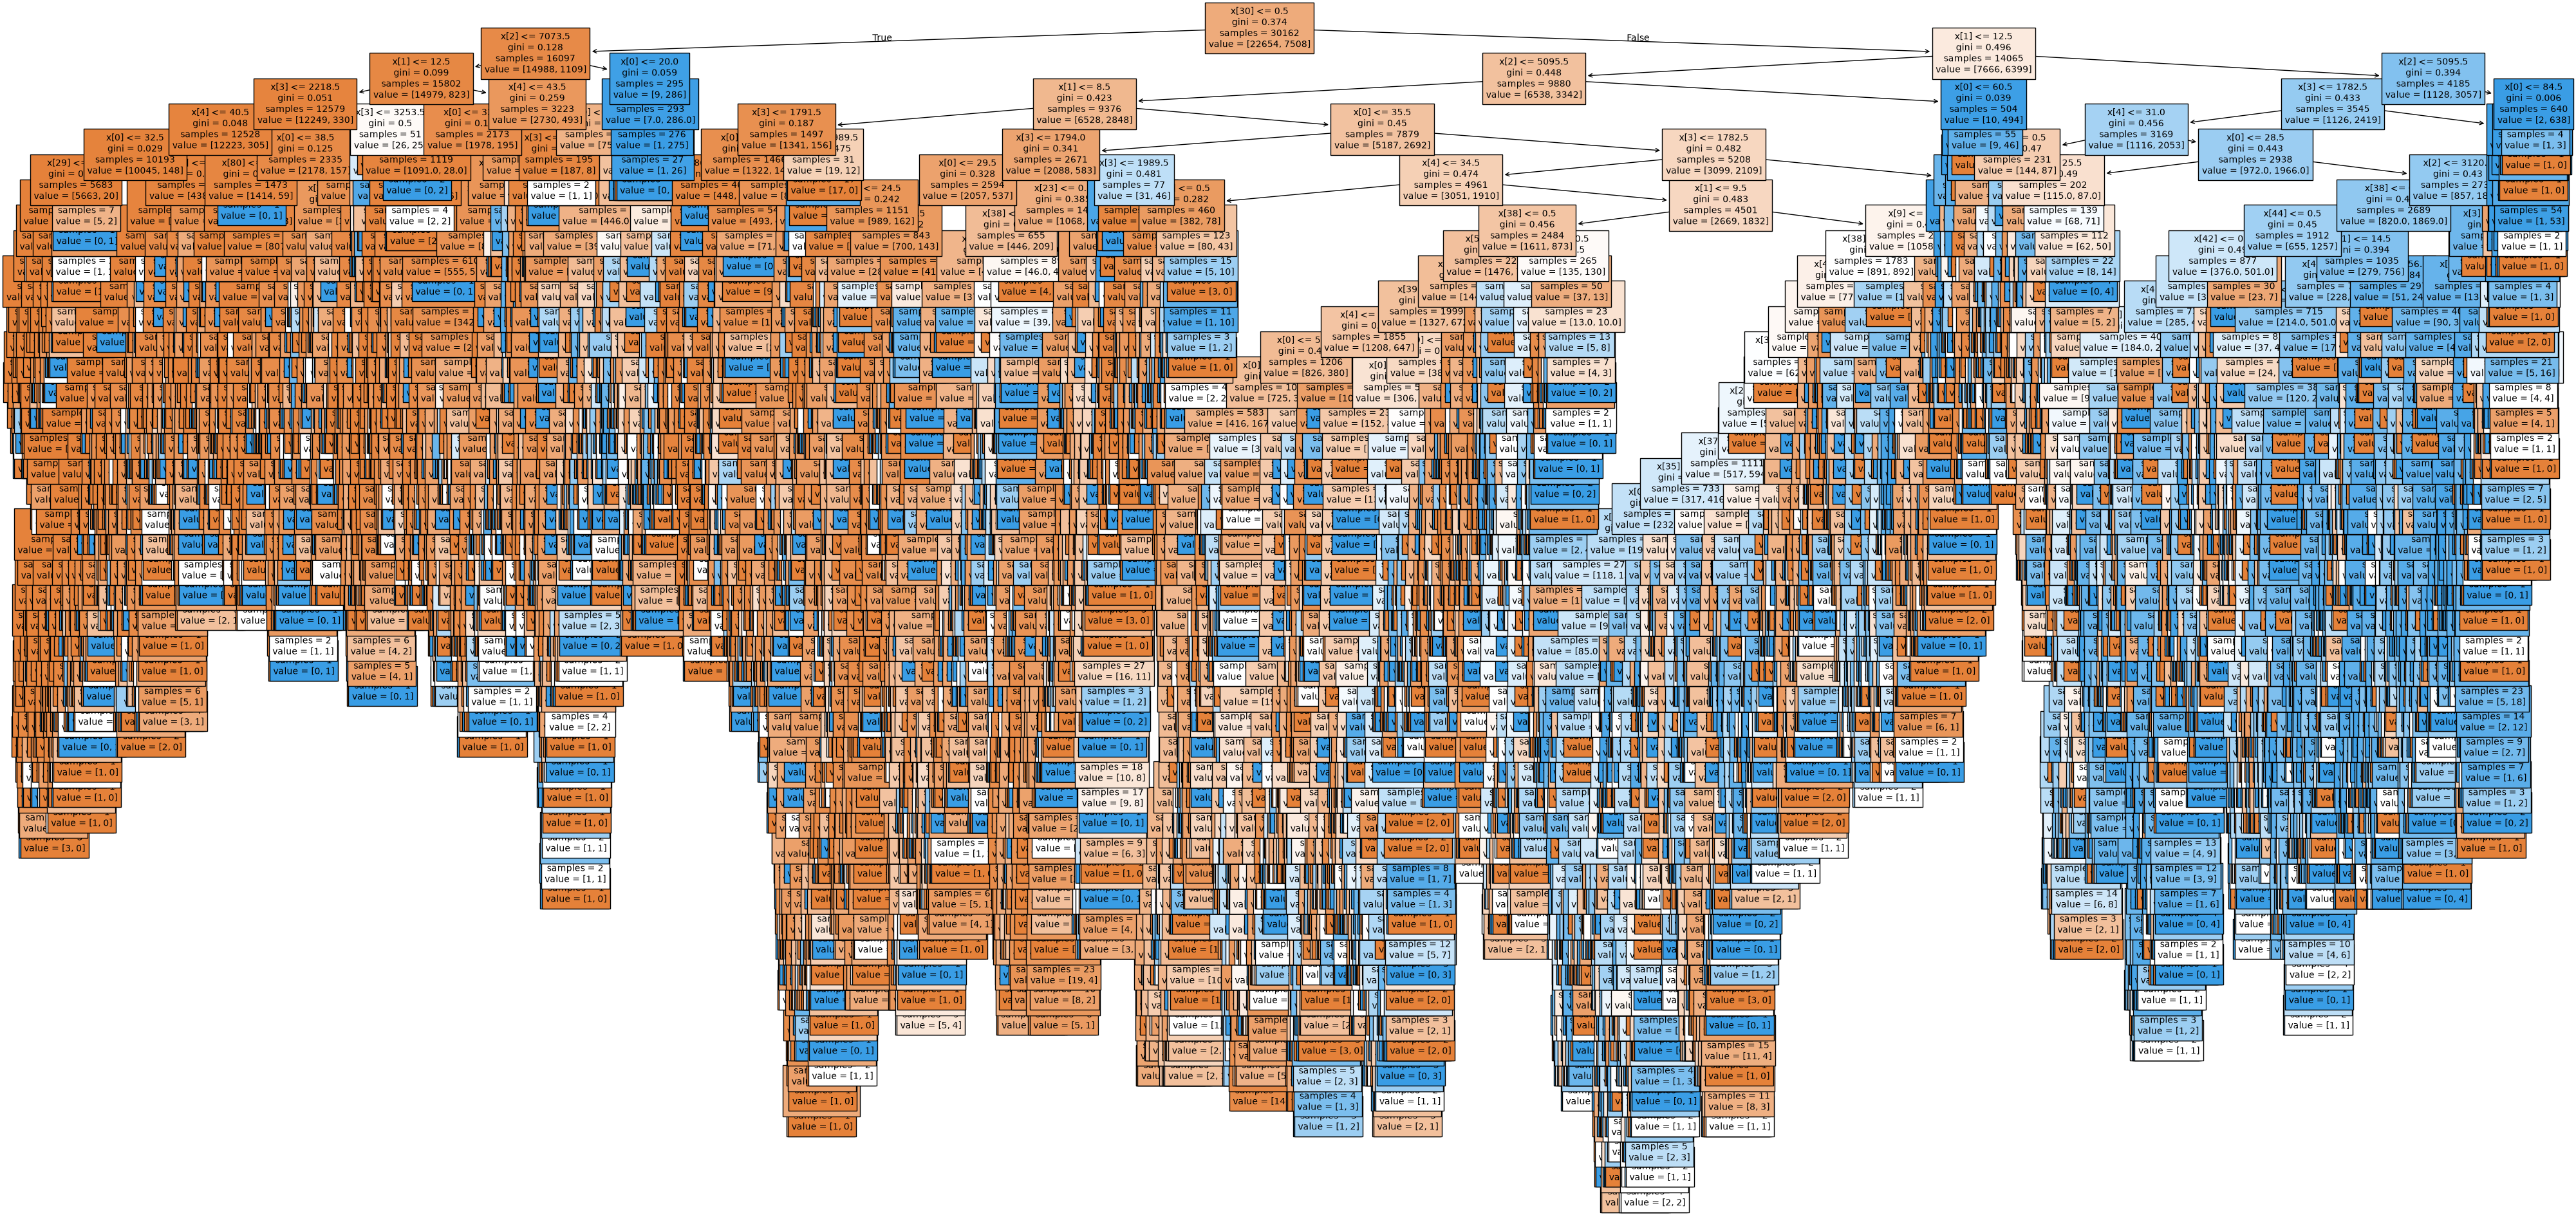

In [23]:
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_gini, filled=True, fontsize=10)
plt.savefig('decision_tree_gini', dpi=100)
plt.show()

Đặng Phan Duy - 6451071010

## Câu 9

In [24]:
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

In [25]:
# Model Accuracy, how often is the classifier correct?
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:", metrics.classification_report(y_test, bayes_pred))

Accuracy: 0.8029216467463479
Report:               precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



Đặng Phan Duy - 6451071010

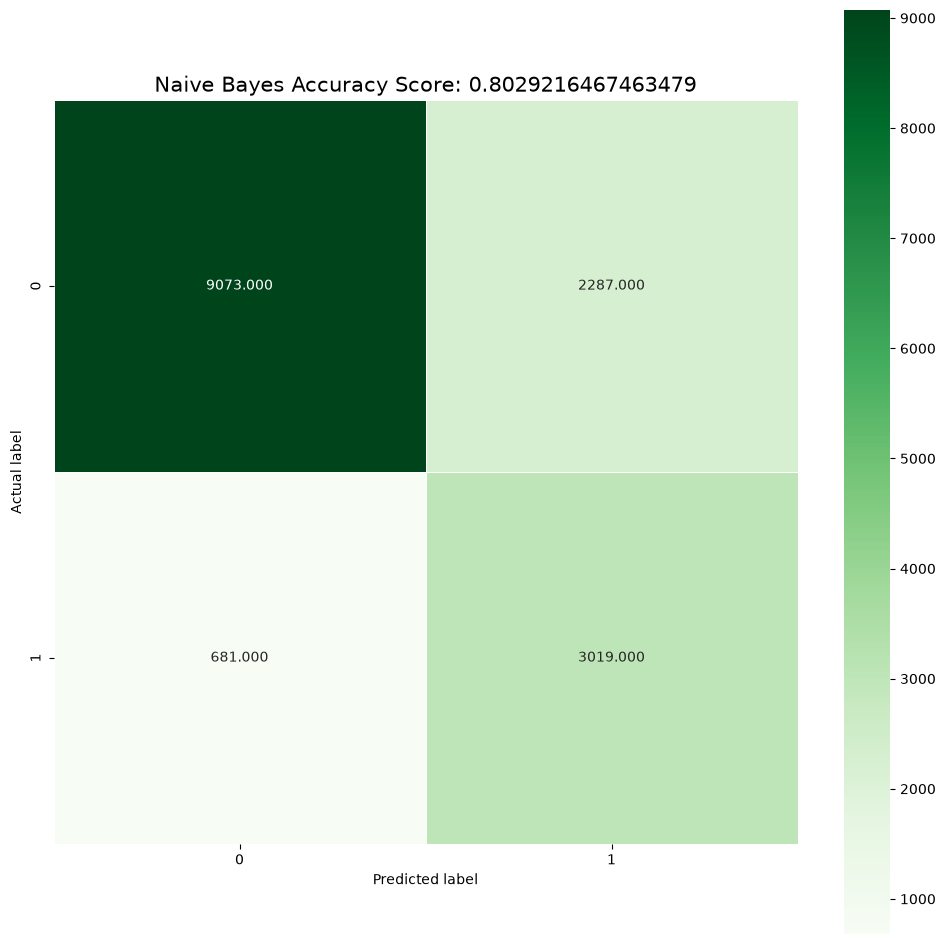

In [26]:
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)

plt.figure(figsize=(12,12))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Greens');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Naive Bayes Accuracy Score: {0}'.format(bayes_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

## Câu 10

In [27]:
results = pd.DataFrame({
    'Model': ['ID3', 'CART', 'Naive Bayes'],
    'Accuracy': [tree_score, gini_score, bayes_score],
    'Precision (>50K)': [metrics.precision_score(y_test, p, pos_label='>50K') for p in [tree_pred, gini_pred, bayes_pred]],
    'Recall (>50K)': [metrics.recall_score(y_test, p, pos_label='>50K') for p in [tree_pred, gini_pred, bayes_pred]],
    'F1 (>50K)': [metrics.f1_score(y_test, p, pos_label='>50K') for p in [tree_pred, gini_pred, bayes_pred]]
})
results

,Model,Accuracy,Precision (>50K),Recall (>50K),F1 (>50K)
0,ID3,0.817530,0.631856,0.616486,0.624077
1,CART,0.812284,0.622098,0.601081,0.611409
2,Naive Bayes,0.802922,0.568979,0.815946,0.670442


Đặng Phan Duy - 6451071010

Nhận xét:

- Về độ chính xác tổng thể (accuracy), cây ID3 đạt cao nhất (≈ 0.8175), tiếp theo là cây CART (≈ 0.8123) và thấp nhất là Naïve Bayes (≈ 0.8029). Tuy nhiên chênh lệch giữa ba mô hình là không lớn (chưa tới 1.5%).
- Hai cây quyết định ID3 và CART cho kết quả rất gần nhau: precision và recall của lớp '<=50K' đều khoảng 0.87 - 0.88, của lớp '>50K' khoảng 0.60 - 0.63. Hai cây đều rất lớn và sâu (phát triển đến khi các nút lá thuần nhất) nên dễ bị quá khớp (overfitting) với dữ liệu huấn luyện.
- Naïve Bayes có recall của lớp '>50K' cao hơn hẳn (≈ 0.82 so với ≈ 0.60 - 0.62 của hai cây), tức là phát hiện được nhiều người có thu nhập >50K hơn, nhưng đổi lại precision của lớp này thấp hơn (≈ 0.57) do dự đoán nhầm nhiều người '<=50K' thành '>50K' (2287 trường hợp). Nhờ recall cao, F1-score của lớp '>50K' của Naïve Bayes (≈ 0.67) lại cao hơn hai cây (≈ 0.61 - 0.62), và macro avg recall cũng cao hơn (0.81 so với 0.74 - 0.75).
- Dữ liệu bị mất cân bằng (11360 mẫu '<=50K' so với 3700 mẫu '>50K'), nên accuracy chủ yếu phản ánh lớp đa số. Nếu cần dự đoán chính xác tổng thể thì nên chọn cây ID3; nếu cần phát hiện tốt những người có thu nhập >50K thì Naïve Bayes là lựa chọn phù hợp hơn.